In [2]:
from coffea.nanoevents import NanoEventsFactory
import awkward as ak
import numpy as np
import hist
import pandas as pd
import uproot
import json
import glob
import matplotlib.pyplot as plt
import mplhep as hep
from pathlib import Path


hep.style.use("CMS")


from common_bb_cc import common_mc, data_by_year# , higgs_mc#data_by_year_muon, data_by_year_zgamma
from hbb import utils

/uscms_data/d3/bweiss/micromamba/envs/hbb/lib/python3.10/site-packages/coffea/nanoevents/schemas/fcc.py:5: FutureWarning: In version 2025.1.0 (target date: 2024-12-31 11:59:59-06:00), this will be an error.
To raise these warnings as errors (and get stack traces to find out where they're called), run
    import warnings
    warnings.filterwarnings("error", module="coffea.*")
after the first `import coffea` or use `@pytest.mark.filterwarnings("error:::coffea.*")` in pytest.
Issue: coffea.nanoevents.methods.vector will be removed and replaced with scikit-hep vector. Nanoevents schemas internal to coffea will be migrated. Otherwise please consider using that package!.
  from coffea.nanoevents.methods import vector


In [3]:
with open("../../workingpoints.json", "r", encoding="utf-8") as file:
    WP = json.load(file)

print(WP[0].keys())
WP_df = pd.DataFrame(WP)

WP_df['pt_bin'] = 0
WP_df['pt_bin']= (WP_df['pt_low']==50.0).astype(int)
WP_df['eta_bin'] = (WP_df['eta_low']==1.3).astype(int)

dict_keys(['tagger', 'pt_low', 'pt_high', 'eta_low', 'eta_high', 'threshold', 'tpr', 'fpr', 'target_type', 'target_value'])


In [4]:
print(WP_df[['threshold', 'pt_high', 'pt_bin', 'eta_high', 'eta_bin']])
# WP_df = WP_df.sort_values(by='fpr')
# print(WP_df[['threshold', 'pt_bin', 'eta_bin', 'target_type', 'target_value', 'fpr']])
thresh_dict = {}
for pt_bin in range(2):
    eta_dict = {}
    for eta_bin in range(2):
        bin_selection = (WP_df['eta_bin']==eta_bin)&(WP_df['pt_bin']==pt_bin)
        WP_df_bin = WP_df[bin_selection].sort_values(by='threshold', ignore_index=True)
        # print(WP_df_bin)
        thresholds = {}
        for wp in range(5):
            up = WP_df_bin.loc[2*wp+1]
            down = WP_df_bin.loc[2*wp]
            thresh = up['threshold'] if (up['fpr']- up['target_value']) < (down['fpr']- down['target_value']) else down['threshold']
            thresholds[str(int(wp))] = thresh
        eta_dict[f'eta_bin_{eta_bin}'] = thresholds
    thresh_dict[f'pt_bin_{pt_bin}']= eta_dict
        
print(thresh_dict)


    threshold  pt_high  pt_bin  eta_high  eta_bin
0        0.40     50.0       0       1.3        0
1        0.48     50.0       0       1.3        0
2        0.52     50.0       0       1.3        0
3        0.66     50.0       0       1.3        0
4        0.74     50.0       0       1.3        0
5        0.42     50.0       0       2.5        1
6        0.50     50.0       0       2.5        1
7        0.56     50.0       0       2.5        1
8        0.68     50.0       0       2.5        1
9        0.76     50.0       0       2.5        1
10       0.40     70.0       1       1.3        0
11       0.48     70.0       1       1.3        0
12       0.54     70.0       1       1.3        0
13       0.68     70.0       1       1.3        0
14       0.76     70.0       1       1.3        0
15       0.44     70.0       1       2.5        1
16       0.52     70.0       1       2.5        1
17       0.58     70.0       1       2.5        1
18       0.70     70.0       1       2.5        1


In [4]:
MAIN_DIR = "/eos/uscms/store/group/lpchbbrun3/"
# dir_name = "skims/26May18/"
dir_name = "skims/26Jun12/"
# dir_name = "lzygala/26Jun12_v15/"
# year='2024'
# years = ['2022', '2022EE', '2023','2023BPix', #'2024'
#         ]
years = ['2022']

samples = {**common_mc}

qcd = samples['qcd']
print(qcd)
# with open('input_vars.json', 'r', encoding='utf-8') as file:
#     ivs = json.load(file)
# print(ivs)

load_columns = ["weight", 'FatJet0_ParTmassX2p', "FatJet0_ParTPXbbXcc", 'Jet0_pt', 'Jet0_eta', 'Jet0_btagPNetQvG', 
                #"FatJet0_ParTPXccVsQCD", "FatJet0_ParTPXbbVsQCD", "BDT_score"
               ]
# load_columns = ivs.keys()
# print(load_columns)

{'QCD_HT-600to800', 'QCD_HT-1000to1200', 'QCD_HT-100to200', 'QCD_HT-1500to2000', 'QCD_HT-800to1000', 'QCD_HT-200to400', 'QCD_HT-40to70', 'QCD_HT-2000', 'QCD_HT-70to100', 'QCD_HT-400to600', 'QCD_HT-1200to1500'}


In [5]:
for year in years:
    path_to_dir = f"{MAIN_DIR}/{dir_name}/"
    data_dir = Path(path_to_dir) / year
    MC = pd.DataFrame()
    data = pd.DataFrame()
    for dataset in qcd:
        print(dataset)
        events = utils.load_samples(
            data_dir,
            {'qcd': [dataset]},
            columns=load_columns,
            region='signal-all',
            filters=None,
        )
        if events:
            MC = pd.concat([MC, events['qcd']])
    
    for dataset in data_by_year[year]:
        print(dataset)
        events = utils.load_samples(
            data_dir,
            {'data': [dataset]},
            columns=load_columns,
            region='signal-all',
            filters=None,
        )
        if events:
            data = pd.concat([data, events['data']])
    

NameError: name 'years' is not defined

In [ ]:
MC['QvG_bin'] = -1
    
data['QvG_bin'] = -1
# print(data.head())
pt_bins = {0: [30,50], 1:[50, 1e4]}
eta_bins = {0: [0,1.3], 1:[1.3, 2.5]}
for pt_bin, pt_range in pt_bins.items():
    for eta_bin, eta_range in eta_bins.items():
        pt_selection_mc = (MC['Jet0_pt']> pt_range[0]) & (MC['Jet0_pt']<pt_range[1])
        eta_selection_mc = (abs(MC['Jet0_eta'])> eta_range[0]) & (abs(MC['Jet0_eta'])<eta_range[1])
        pt_selection_data = (data['Jet0_pt']> pt_range[0]) & (data['Jet0_pt']<pt_range[1])
        eta_selection_data = (abs(data['Jet0_eta'])> eta_range[0]) & (abs(data['Jet0_eta'])<eta_range[1])
        for wp in range(5):
            wp_down = thresh_dict[f'pt_bin_{pt_bin}'][f'eta_bin_{eta_bin}'][str(wp)]
            if wp == 4:
                wp_up = 1
            else:
                wp_up = thresh_dict[f'pt_bin_{pt_bin}'][f'eta_bin_{eta_bin}'][str(wp+1)]
            wp_selection_mc = (wp_down<MC['Jet0_btagPNetQvG']) & (MC['Jet0_btagPNetQvG']<wp_up)
            wp_selection_data = (wp_down<data['Jet0_btagPNetQvG']) & (data['Jet0_btagPNetQvG']<wp_up)

            # print(pt_bin, eta_bin, wp, sum(wp_selection & pt_selection))
            data.loc[wp_selection_data & pt_selection_data & eta_selection_data, 'QvG_bin'] = wp
            MC.loc[wp_selection_mc & pt_selection_mc & eta_selection_mc, 'QvG_bin'] = wp
            
print(MC[['Jet0_btagPNetQvG', 'QvG_bin', 'Jet0_pt', 'Jet0_eta', ]])
print(data[['Jet0_btagPNetQvG', 'QvG_bin', 'Jet0_pt', 'Jet0_eta', ]])
        # this_corr = data.corr(method='pearson')['FatJet0_ParTmassX2p'][iv]
        # corr = pd.concat([corr, pd.DataFrame({'IV': [iv,], 'R': [this_corr,]})], axis = 0,  ignore_index=True)
        # print(len(data))
        # print(len(corr), {'IV': [iv,], 'R': [this_corr,]})

Text(0.5, 0.98, 'WP binned QvG score (2022 QCD)')

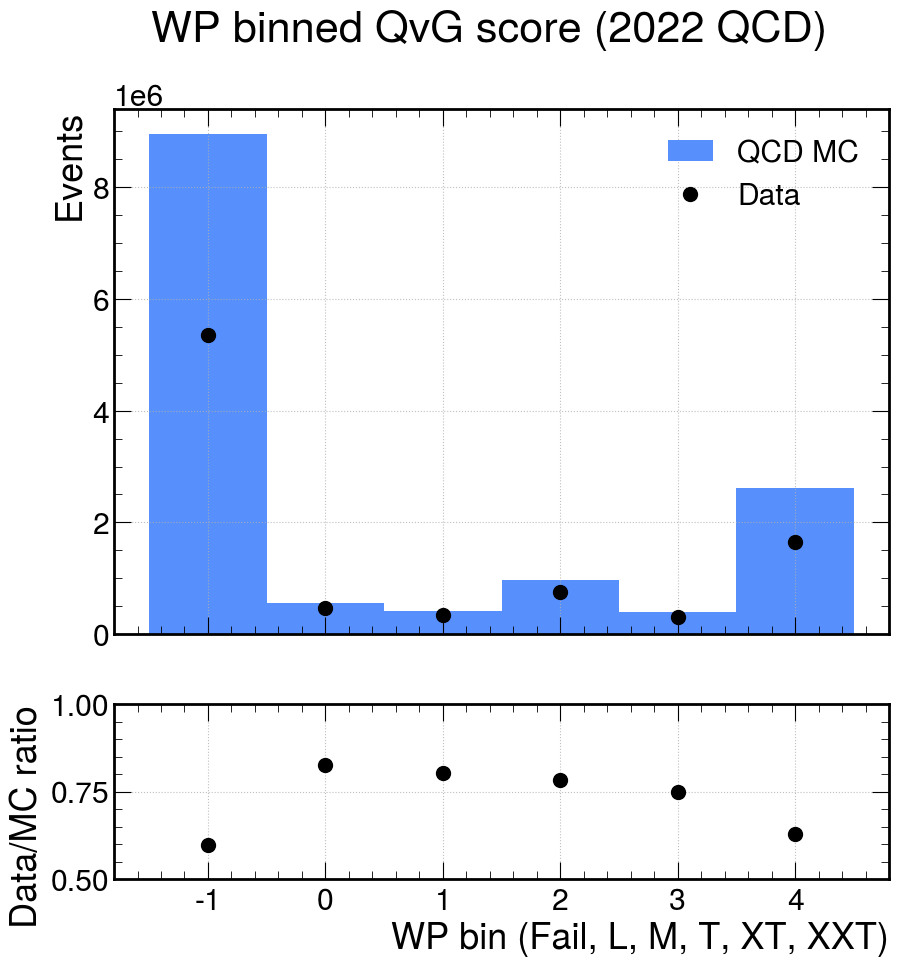

In [28]:
fig, (ax, rax) = plt.subplots(2, 1, gridspec_kw={"height_ratios": (3, 1)}, sharex=True)

MC_counts, bins, patches = ax.hist(MC['QvG_bin'], weights = MC['finalWeight'],label = 'QCD MC', bins =[-1.5,-0.5,0.5,1.5,2.5,3.5,4.5,])
data_counts, bin_edges = np.histogram(data['QvG_bin'], weights = data['finalWeight'], bins =[-1.5,-0.5,0.5,1.5,2.5,3.5,4.5,])

ratio = data_counts/MC_counts
ax.plot([-1,0,1,2,3,4], data_counts, color='black', marker = 'o', markersize = 10, lw=0, label = 'Data')

rax.plot([-1,0,1,2,3,4], ratio, color='black', marker = 'o', markersize = 10, lw=0)
rax.set_ylim([0.5,1])
ax.set_ylabel('Events')
rax.set_xlabel('WP bin (Fail, L, M, T, XT, XXT)')
rax.set_ylabel('Data/MC ratio')
ax.legend()
ax.grid()
rax.grid()
fig.suptitle('WP binned QvG score (2022 QCD)')

In [1]:
import correctionlib

correction_file = 'output_Jul_16_v1/SF/correctionlib/qg_tagging_SF.json.gz'
evaluator = correctionlib.CorrectionSet.from_file(correction_file)

print(type(evaluator), dir(evaluator))

<class 'correctionlib.highlevel.CorrectionSet'> ['__abstractmethods__', '__annotations__', '__class__', '__class_getitem__', '__contains__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__iter__', '__le__', '__len__', '__lt__', '__module__', '__ne__', '__new__', '__orig_bases__', '__parameters__', '__reduce__', '__reduce_ex__', '__repr__', '__reversed__', '__setattr__', '__setstate__', '__sizeof__', '__slots__', '__str__', '__subclasshook__', '__weakref__', '_abc_impl', '_base', '_data', '_ipython_key_completions_', '_is_protocol', 'compound', 'from_file', 'from_string', 'get', 'items', 'keys', 'schema_version', 'values']
